# 01 — Exploration des données

C'est la **toute première étape du projet** : regarder à quoi ressemblent les données avant d'écrire `clean.py`.
C'est ici qu'on a trouvé les noms exacts des opérateurs, les libellés 4G/5G et les colonnes utiles.
Tout ce qu'on a appris est rangé dans `DICTIONNAIRE_DONNEES.md`.

1. Récupérer les données brutes (via `collect.py`)
2. **ANFR** : les tables, puis les 4 tables utiles
3. **ANFR** : les 4 opérateurs, les technologies (4G/5G), une première jointure et une carte
4. **Arcep** : le fichier des mesures de terrain
5. Ce qu'on en a retenu, et les fichiers que le pipeline produit au final (`data/`)

> Pour lancer ce notebook dans VS Code : `pip install -r requirements.txt matplotlib ipykernel`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
ANFR = Path("data_raw/anfr")
ARCEP = Path("data_raw/arcep")

def lire_anfr(nom, **kw):
    """Lit une table ANFR : séparateur ;  tout en texte (garde les zéros de tête)."""
    for enc in ["utf-8", "latin-1"]:
        try:
            return pd.read_csv(ANFR / f"{nom}.txt", sep=";", dtype=str, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue

## 1. Récupérer les données brutes

Le dépôt ne contient que les fichiers **déjà nettoyés** (`data/`) : `clean.py` supprime les fichiers bruts une fois traités.
Pour explorer, on les retélécharge avec `collect.py` en mode `forcer=True` (via l'API data.gouv.fr, ~300 Mo, quelques minutes).

Ils arrivent dans `data_raw/`. Après l'exploration, on peut supprimer ce dossier
(sinon, le prochain `run.sh` les nettoiera puis les supprimera tout seul).

In [2]:
from pipeline import collect

if not any(ANFR.glob("SUP_*.txt")):
    collect.collect_anfr(forcer=True)
if not any(ARCEP.glob("*.csv")):
    collect.collect_arcep(forcer=True)

for f in sorted(ANFR.glob("*.txt")) + sorted(ARCEP.glob("*.csv")):
    print(f"{f.name:45} {f.stat().st_size / 1e6:8.1f} Mo")

ANFR : téléchargement de Tables supports antennes émetteurs bandes novembre 2026


ANFR : téléchargement de Tables de référence novembre 2026


ANFR OK


ARCEP : téléchargement de 2025_QoS_Metropole_data_habitations.csv


ARCEP OK
SUP_EMETTEUR.txt                                 116.5 Mo
SUP_EXPLOITANT.txt                                 0.0 Mo
SUP_NATURE.txt                                     0.0 Mo
SUP_PROPRIETAIRE.txt                               0.0 Mo
SUP_STATION.txt                                   11.2 Mo
SUP_SUPPORT.txt                                   18.7 Mo
SUP_TYPE_ANTENNE.txt                               0.0 Mo
2025_QoS_Metropole_data_habitations.csv           93.3 Mo


## 2. ANFR — vue d'ensemble des tables

L'ANFR publie **9 tables**. `collect.py` supprime tout de suite les 2 plus lourdes, qui ne nous servent pas :
`SUP_BANDE` (fréquences détaillées) et `SUP_ANTENNE` (caractéristiques physiques des antennes), ~235 Mo à elles deux. Il en reste 7.

Pour chaque table : nombre de colonnes, noms des colonnes, et 3 premières lignes.
(On ne lit que 1 000 lignes ici pour aller vite.)

In [3]:
for f in sorted(ANFR.glob("SUP_*.txt")):
    df = lire_anfr(f.stem, nrows=1000)
    print(f"\n=== {f.stem}  ({df.shape[1]} colonnes)")
    print(list(df.columns))
    display(df.head(3))


=== SUP_EMETTEUR  (5 colonnes)
['EMR_ID', 'EMR_LB_SYSTEME', 'STA_NM_ANFR', 'AER_ID', 'EMR_DT_SERVICE']


,EMR_ID,EMR_LB_SYSTEME,STA_NM_ANFR,AER_ID,EMR_DT_SERVICE
0,850,FM,0010130127,850,NaN
1,918,FM,0040130034,918,26/07/1996
2,924,FM,0040130154,924,19/07/2023



=== SUP_EXPLOITANT  (2 colonnes)
['ADM_ID', 'ADM_LB_NOM']


,ADM_ID,ADM_LB_NOM
0,149,AFRIPA TELECOM
1,2,RESEAU PRIVE
2,3,ANFR / DTCG



=== SUP_NATURE  (2 colonnes)
['NAT_ID', 'NAT_LB_NOM']


,NAT_ID,NAT_LB_NOM
0,0,Sans nature
1,40,Sémaphore
2,41,Phare


... (4 outputs left out)


=== SUP_SUPPORT  (19 colonnes)
['SUP_ID', 'STA_NM_ANFR', 'NAT_ID', 'COR_NB_DG_LAT', 'COR_NB_MN_LAT', 'COR_NB_SC_LAT', 'COR_CD_NS_LAT', 'COR_NB_DG_LON', 'COR_NB_MN_LON', 'COR_NB_SC_LON', 'COR_CD_EW_LON', 'SUP_NM_HAUT', 'TPO_ID', 'ADR_LB_LIEU', 'ADR_LB_ADD1', 'ADR_LB_ADD2', 'ADR_LB_ADD3', 'ADR_NM_CP', 'COM_CD_INSEE']


,SUP_ID,STA_NM_ANFR,NAT_ID,COR_NB_DG_LAT,COR_NB_MN_LAT,COR_NB_SC_LAT,COR_CD_NS_LAT,COR_NB_DG_LON,COR_NB_MN_LON,COR_NB_SC_LON,COR_CD_EW_LON,SUP_NM_HAUT,TPO_ID,ADR_LB_LIEU,ADR_LB_ADD1,ADR_LB_ADD2,ADR_LB_ADD3,ADR_NM_CP,COM_CD_INSEE
0,74167,0162290002,23,46,0,13,N,0,21,19,E,41,74,La Range,NaN,NaN,NaN,16350,16404
1,1121219,0160230003,11,45,41,43,N,0,20,57,W,15,13,NaN,BOULEVARD JAVREZAC,NaN,NaN,16100,16102
2,1121239,0160230004,17,45,38,14,N,0,7,51,E,8,13,NaN,Rue de la Brigade Rac,NaN,NaN,16000,16015



=== SUP_TYPE_ANTENNE  (2 colonnes)
['TAE_ID', 'TAE_LB']


,TAE_ID,TAE_LB
0,75,Antenne Ran-Sharing
1,76,Tube
2,0,Sans type


## 3. ANFR — les 4 tables utiles, en entier

- **SUP_STATION** : le site + le code de l'exploitant
- **SUP_EXPLOITANT** : le nom de l'exploitant
- **SUP_EMETTEUR** : la technologie émise
- **SUP_SUPPORT** : la position et la commune

On ne charge que les colonnes utiles, pour économiser la mémoire.

In [4]:
station = lire_anfr("SUP_STATION", usecols=["STA_NM_ANFR", "ADM_ID", "DTE_EN_SERVICE"])
exploitant = lire_anfr("SUP_EXPLOITANT")
emetteur = lire_anfr("SUP_EMETTEUR", usecols=["STA_NM_ANFR", "EMR_LB_SYSTEME", "EMR_DT_SERVICE"])
support = lire_anfr("SUP_SUPPORT", usecols=[
    "STA_NM_ANFR", "SUP_ID",
    "COR_NB_DG_LAT", "COR_NB_MN_LAT", "COR_NB_SC_LAT", "COR_CD_NS_LAT",
    "COR_NB_DG_LON", "COR_NB_MN_LON", "COR_NB_SC_LON", "COR_CD_EW_LON",
    "COM_CD_INSEE",
])

for nom, df in [("station", station), ("exploitant", exploitant), ("emetteur", emetteur), ("support", support)]:
    print(f"{nom:12} {df.shape[0]:>9,} lignes  |  % de valeurs manquantes :")
    print((df.isna().mean() * 100).round(1).to_string(), "\n")

station        198,174 lignes  |  % de valeurs manquantes :
STA_NM_ANFR       0.0
ADM_ID            0.0
DTE_EN_SERVICE    4.5 

exploitant         189 lignes  |  % de valeurs manquantes :
ADM_ID        0.0
ADM_LB_NOM    0.0 

emetteur     2,464,000 lignes  |  % de valeurs manquantes :
EMR_LB_SYSTEME    0.0
STA_NM_ANFR       0.0
EMR_DT_SERVICE    8.8 

support        199,290 lignes  |  % de valeurs manquantes :
SUP_ID           0.0
STA_NM_ANFR      0.0
COR_NB_DG_LAT    0.0
COR_NB_MN_LAT    0.0
COR_NB_SC_LAT    0.0
COR_CD_NS_LAT    0.0
COR_NB_DG_LON    0.0
COR_NB_MN_LON    0.0
COR_NB_SC_LON    0.0
COR_CD_EW_LON    0.0
COM_CD_INSEE     0.0 



## 4. Qui exploite les sites ?

La base contient **tous** les exploitants (radios, réseaux privés, police…).
On regarde les plus gros, puis on cherche nos 4 opérateurs.

In [5]:
station_nom = station.merge(exploitant, on="ADM_ID", how="left")
station_nom["ADM_LB_NOM"].value_counts().head(20)

ADM_LB_NOM
BOUYGUES TELECOM              35379
ORANGE                        34815
FREE MOBILE                   33830
SFR                           33183
TDF                           12683
RESEAU PRIVE                  12275
ORANGE service fixe            7725
TOWERCAST                      6320
Site privé                     4682
SNCF Réseau                    4189
EDF                            3147
Conseils Départementaux        1023
Direction Des Routes           1009
PNM                             862
Gouv Nelle Calédonie (OPT)      850
OUTREMER TELECOM                547
DIGICEL                         492
SRR                             479
FREE CARAIBES                   473
ONATI                           453
Name: count, dtype: int64

In [6]:
# Les noms exacts de nos 4 opérateurs (à noter pour clean.py)
mask_4 = station_nom["ADM_LB_NOM"].str.contains("ORANGE|SFR|BOUYGUES|FREE", case=False, na=False)
station_nom.loc[mask_4, ["ADM_ID", "ADM_LB_NOM"]].value_counts()

ADM_ID  ADM_LB_NOM         
6       BOUYGUES TELECOM       35379
23      ORANGE                 34815
240     FREE MOBILE            33830
137     SFR                    33183
21      ORANGE service fixe     7725
307     FREE CARAIBES            473
Name: count, dtype: int64

## 5. Quelles technologies ?

`EMR_LB_SYSTEME` dit ce que chaque émetteur émet. On regarde **uniquement chez nos 4 opérateurs**,
pour repérer les libellés 4G (souvent « LTE … ») et 5G (souvent « 5G NR … »).

In [7]:
sites_4 = station_nom.loc[mask_4, ["STA_NM_ANFR", "ADM_LB_NOM"]]
emetteur_4 = emetteur.merge(sites_4, on="STA_NM_ANFR", how="inner")

emetteur_4["EMR_LB_SYSTEME"].value_counts()

EMR_LB_SYSTEME
LTE 700                 307934
LTE 1800                303692
LTE 800                 298168
UMTS 900                277159
LTE 2100                232309
LTE 2600                223553
5G NR 3500              161598
5G NR 2100              123962
5G NR 700               122104
GSM 900                 111890
LTE 900                  79486
FH                       76515
UMTS 2100                18455
GSM 1800                  1149
FH ABI                     226
SAT GEO                     54
5G NR 1400 Expe             17
BLR LTE 3500                 6
5G NR 3800-4200 Expe         6
SAT NGEO                     4
5G NR 26 GHz Expe            1
Name: count, dtype: int64

In [8]:
# Répartition par opérateur et par technologie
pd.crosstab(emetteur_4["EMR_LB_SYSTEME"], emetteur_4["ADM_LB_NOM"])

ADM_LB_NOM,BOUYGUES TELECOM,FREE CARAIBES,FREE MOBILE,ORANGE,ORANGE service fixe,SFR
EMR_LB_SYSTEME,,,,,,
5G NR 1400 Expe,0,0,0,17,0,0
5G NR 2100,64507,0,127,13524,0,45804
5G NR 26 GHz Expe,0,0,0,1,0,0
5G NR 3500,38028,194,38280,48621,0,36475
5G NR 3800-4200 Expe,0,0,0,6,0,0
5G NR 700,0,162,76656,45286,0,0
BLR LTE 3500,0,0,0,6,0,0
FH,24756,0,21970,0,11261,18528
FH ABI,0,0,0,0,226,0


## 6. Positions : conversion en latitude / longitude décimales

Les coordonnées sont en **degrés / minutes / secondes** + N/S et E/W.
Formule : `degrés + minutes/60 + secondes/3600`, négatif si Sud ou Ouest.

In [9]:
def en_decimal(deg, minu, sec, sens, negatif):
    num = lambda s: pd.to_numeric(s.str.replace(",", "."), errors="coerce")
    val = num(deg) + num(minu) / 60 + num(sec) / 3600
    return val.where(sens != negatif, -val)

support["lat"] = en_decimal(support["COR_NB_DG_LAT"], support["COR_NB_MN_LAT"],
                            support["COR_NB_SC_LAT"], support["COR_CD_NS_LAT"], "S")
support["lon"] = en_decimal(support["COR_NB_DG_LON"], support["COR_NB_MN_LON"],
                            support["COR_NB_SC_LON"], support["COR_CD_EW_LON"], "W")

support[["STA_NM_ANFR", "COM_CD_INSEE", "lat", "lon"]].describe(include="all")

,STA_NM_ANFR,COM_CD_INSEE,lat,lon
count,199290,199290,199290.000000,199290.000000
unique,198174,23488,NaN,NaN
top,0281570001,31555,NaN,NaN
freq,58,1003,NaN,NaN
mean,NaN,NaN,44.380604,2.281003
std,NaN,NaN,11.215102,19.983005
min,NaN,NaN,-66.665278,-178.171389
25%,NaN,NaN,44.261667,0.972778
50%,NaN,NaN,46.435000,2.741667
75%,NaN,NaN,48.620000,5.153333


In [10]:
# Un site peut-il avoir plusieurs supports ?
support.groupby("STA_NM_ANFR").size().value_counts().head()

1    197441
2       626
3        72
4        13
5         6
Name: count, dtype: int64

## 7. Première jointure : 1 ligne par site × opérateur × technologie

Juste pour **voir** le résultat — le vrai nettoyage sera dans `clean.py`.

In [11]:
apercu = (
    emetteur_4[["STA_NM_ANFR", "ADM_LB_NOM", "EMR_LB_SYSTEME"]]
    .drop_duplicates()
    .merge(support.drop_duplicates("STA_NM_ANFR")[["STA_NM_ANFR", "COM_CD_INSEE", "lat", "lon"]],
           on="STA_NM_ANFR", how="left")
)
print(apercu.shape)
apercu.head(10)

(837993, 6)


,STA_NM_ANFR,ADM_LB_NOM,EMR_LB_SYSTEME,COM_CD_INSEE,lat,lon
0,0012700021,SFR,GSM 900,01194,45.979722,4.763889
1,0012700009,SFR,GSM 900,01185,45.962222,5.620833
2,0012700032,SFR,GSM 900,01286,45.747222,5.731944
3,0012700006,SFR,GSM 900,01244,45.910833,5.202222
4,0012700016,SFR,GSM 900,01140,46.267222,5.107778
5,0012700020,SFR,GSM 900,01258,46.086111,4.783056
6,0012700023,SFR,GSM 900,01248,45.895833,4.896667
7,0012700031,SFR,GSM 900,01262,45.850556,5.059722
8,0012700043,SFR,GSM 900,01093,46.123333,4.964167
9,0012700041,SFR,GSM 900,01202,45.899444,5.326389


## 8. Une carte rapide (France métropolitaine)

Chaque point = un site d'un des 4 opérateurs.

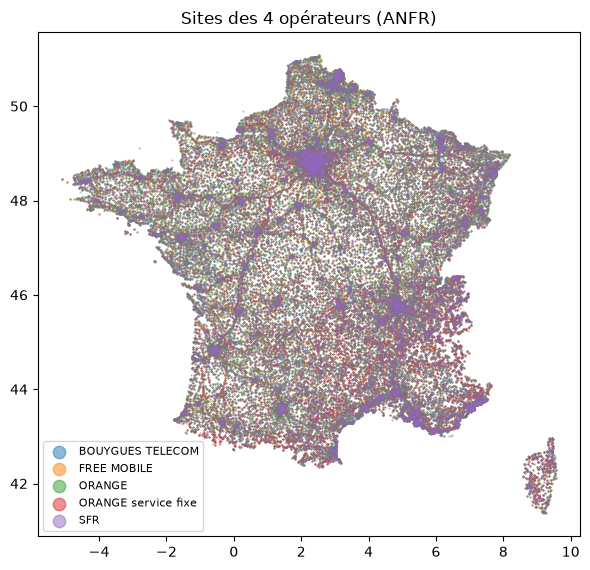

In [12]:
metro = apercu.dropna(subset=["lat", "lon"]).drop_duplicates("STA_NM_ANFR")
metro = metro[metro["lat"].between(41, 51.5) & metro["lon"].between(-5.5, 10)]

fig, ax = plt.subplots(figsize=(7, 7))
for nom, groupe in metro.groupby("ADM_LB_NOM"):
    ax.scatter(groupe["lon"], groupe["lat"], s=0.2, label=nom, alpha=0.5)
ax.set_title("Sites des 4 opérateurs (ANFR)")
ax.legend(markerscale=20, fontsize=8)
ax.set_aspect(1.4)
plt.show()

In [13]:
# Exemple : une commune (Nanterre = 92050). Change le code pour tester la tienne.
CODE = "92050"
ville = apercu[apercu["COM_CD_INSEE"] == CODE]
pd.crosstab(ville["EMR_LB_SYSTEME"], ville["ADM_LB_NOM"])

ADM_LB_NOM,BOUYGUES TELECOM,FREE MOBILE,ORANGE,SFR
EMR_LB_SYSTEME,,,,
5G NR 2100,25,0,0,7
5G NR 3500,24,25,21,16
5G NR 700,0,29,19,0
FH,9,0,0,3
GSM 1800,3,0,0,0
GSM 900,14,0,0,18
LTE 1800,31,30,26,23
LTE 2100,8,30,24,22
LTE 2600,27,30,20,20


## 9. Arcep — les mesures de terrain

Au départ, on ne savait pas à quoi ressemblait ce fichier : on regarde ses colonnes et quelques lignes.
`sep=None` laisse pandas deviner le séparateur.

In [14]:
fichier_arcep = sorted(ARCEP.glob("*.csv"))[0]
arcep = pd.read_csv(fichier_arcep, sep=None, engine="python", nrows=5000, encoding="latin-1")
print(fichier_arcep.name, "→", arcep.shape[1], "colonnes")
print(list(arcep.columns))
arcep.head()

2025_QoS_Metropole_data_habitations.csv → 103 colonnes
['acess_duration', 'average_mos_couple', 'axis', 'axis_name', 'axis_precision', 'band_serving', 'band_start', 'bitrate_dl', 'bitrate_ul', 'call_direction', 'call_number', 'call_setup_time_to_alerting', 'call_type', 'cell_id', 'crspa', 'date_time_end', 'date_time_start', 'date_start', 'date_end', 'download_ok', 'hour_start', 'hour_end', 'descoping', 'descoping_reason', 'detail', 'dialed_number', 'dl_superior_3mbps', 'dl_volume', 'ec_n0', 'helicopter_measure', 'id_measure', 'id_sending_terminal', 'imei', 'imsi', 'insee_com', 'insee_dep', 'intra_inter_op_couple', 'lac', 'latitude_end', 'latitude_start', 'list_mos', 'loaded_in_less_10_secondes', 'loaded_in_less_5_secondes', 'longitude_end', 'longitude_start', 'mcc_end', 'mcc_start', 'min_mos', 'min_mos_couple', 'mnc_end', 'mnc_start', 'mos_average', 'nom_com', 'nom_dep', 'nom_reg', 'operator', 'operator_called', 'operator_calling', 'operator_identical', 'operating_system', 'operating_s

,acess_duration,average_mos_couple,axis,axis_name,axis_precision,band_serving,band_start,bitrate_dl,bitrate_ul,call_direction,call_number,call_setup_time_to_alerting,call_type,cell_id,crspa,date_time_end,date_time_start,date_start,date_end,download_ok,hour_start,hour_end,descoping,descoping_reason,detail,...,sms_reception_date_time,sms_sending_date_time,sms_sending_number,sms_success,tac,techno_end,techno_start,terminal,territory,time_to_call,trace_name,traffic_time,transfert_duration,transfert_file_size,ul_volume,upload_ok,url,video_freez_duration,video_initialisation_duration,video_viewing_duration,zone,zone_name,zone_precision,Unnamed: 101,Result
0,"2,64",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23/06/2025,NaN,NaN,10:29:02,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5G,SM-F731B,METROPOLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.assurance-maladie.ameli.fr/qui-som...,NaN,NaN,NaN,Zones intermediaires,Dax,NaN,NaN,Success
1,"2,45",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23/06/2025,NaN,NaN,10:29:02,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5G,SM-F731B,METROPOLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.assurance-maladie.ameli.fr/qui-som...,NaN,NaN,NaN,Zones intermediaires,Dax,NaN,NaN,Success
2,"2,48",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23/06/2025,NaN,NaN,10:29:02,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5G,SM-F731B,METROPOLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.assurance-maladie.ameli.fr/qui-som...,NaN,NaN,NaN,Zones intermediaires,Dax,NaN,NaN,Success
3,"2,25",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23/06/2025,NaN,NaN,10:29:02,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5G,SM-F731B,METROPOLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.assurance-maladie.ameli.fr/qui-som...,NaN,NaN,NaN,Zones intermediaires,Dax,NaN,NaN,Success
4,"3,41",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23/06/2025,NaN,NaN,10:29:15,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5G,SM-F731B,METROPOLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.doctolib.fr/,NaN,NaN,NaN,Zones intermediaires,Dax,NaN,NaN,Success


In [15]:
# Les colonnes texte : quelles valeurs ? (on y cherchera l'opérateur, le type de test, la commune…)
for col in arcep.select_dtypes("object").columns:
    print(f"\n--- {col} ({arcep[col].nunique()} valeurs distinctes)")
    print(arcep[col].value_counts().head(8).to_string())


--- acess_duration (730 valeurs distinctes)
acess_duration
10,01    578
10       156
10,02    104
2,04      42
2,01      41
2,03      40
2,11      39
2,28      37

--- bitrate_dl (404 valeurs distinctes)
bitrate_dl
0              51
470,2134529     3
463,9716814     3
399,4575238     3
255,7502439     3
247,8903073     2
421,962173      2
264,4580076     2

--- bitrate_ul (215 valeurs distinctes)
bitrate_ul
0              22
42,93044012     2
57,93237569     2
45,83938798     2
4,0455272       1
7,245430569     1
4,694628        1
0,612896703     1

--- date_start (6 valeurs distinctes)
date_start
26/06/2025    1324
24/06/2025     992
27/06/2025     823
25/06/2025     815
23/06/2025     660
30/06/2025     386

--- hour_start (2601 valeurs distinctes)
hour_start
09:32:26    8
13:24:01    7
14:33:40    7
14:39:11    7
16:12:32    7
10:55:11    6
13:04:33    6
09:31:04    6

--- operator (4 valeurs distinctes)
operator
SFR         1251
Bouygues    1251
Orange      1250
Free        1248



C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_25400\4106163433.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in arcep.select_dtypes("object").columns:


In [16]:
# Les colonnes numériques (débits, latences, coordonnées…)
print(arcep.notna().mean().sort_values(ascending=False).round(2).to_string())

insee_com                        1.00
date_start                       1.00
hour_start                       1.00
techno_start                     1.00
operator                         1.00
longitude_start                  1.00
latitude_start                   1.00
protocole                        1.00
situation                        1.00
territory                        1.00
terminal                         1.00
Result                           1.00
zone                             1.00
zone_name                        1.00
acess_duration                   0.95
mcc_start                        0.93
mnc_start                        0.93
rsrp                             0.91
rsrq                             0.91
url                              0.90
loaded_in_less_10_secondes       0.73
loaded_in_less_5_secondes        0.73
transfert_file_size              0.18
bitrate_dl                       0.10
quality_correct                  0.05
quality_perfect                  0.05
bitrate_ul  

In [17]:
COLS = ["operator", "insee_com", "date_start", "techno_start", "protocole",
        "situation", "zone", "Result", "rsrp", "bitrate_dl",
        "loaded_in_less_5_secondes", "latitude_start", "longitude_start"]

arcep_full = pd.read_csv(fichier_arcep, sep=None, engine="python", encoding="latin-1",
                         usecols=COLS, dtype=str)

print("Lignes :", len(arcep_full))
print("Communes différentes :", arcep_full["insee_com"].nunique())
print("Période :", arcep_full["date_start"].min(), "→", arcep_full["date_start"].max())
for col in ["techno_start", "protocole", "situation", "zone", "Result"]:
    print(f"\n--- {col}")
    print(arcep_full[col].value_counts().to_string())

Lignes : 354282
Communes différentes : 1614
Période : 01/07/2025 → 31/07/2025

--- techno_start
techno_start
5G    354282

--- protocole
protocole
WEB         253260
DOWNLOAD     33384
ICMP         17328
STREAM       16933
ULH          16695
UPLOAD       16682

--- situation
situation
Outdoor    127055
Indoor     126951
Incar       79654
indoor       8030
outdoor      7874
incar        4718

--- zone
zone
Zones rurales           116589
Zones denses            113902
Zones intermediaires    103573
Zones touristiques       20218

--- Result
Result
Success         293386
Traffic Fail     37148
TimeOut          21040
Drop              2666
Setup Fail          42


## 10. Ce qu'on a retenu pour `clean.py`

- **Les 4 opérateurs** (`ADM_ID` → nom) : `6` BOUYGUES TELECOM, `23` ORANGE, `137` SFR, `240` FREE MOBILE.
  On écarte `21` ORANGE service fixe et `307` FREE CARAIBES (outre-mer).
- **Libellés 4G** : `LTE 700`, `800`, `900`, `1800`, `2100`, `2600` → règle `^LTE \d+$`.
- **Libellés 5G** : `5G NR 700`, `2100`, `3500` → règle `^5G NR \d+$` (on écarte les `5G NR … Expe`, expérimentaux).
  Le reste (GSM = 2G, UMTS = 3G, FH = faisceaux hertziens, satellite…) est ignoré.
- **Plusieurs supports par site ?** Presque jamais (moins de 1 % des sites) → on garde le premier.
- **Positions** : en degrés / minutes / secondes → la fonction `en_decimal` ci-dessus est reprise telle quelle dans `clean.py`.
- **Arcep** : séparateur à deviner, encodage `latin-1`, décimale `,`. Colonnes gardées : `operator`, `latitude_start`,
  `longitude_start`, `protocole`, `Result` (→ test réussi oui / non) et `bitrate_dl` (débit en Mb/s, tests `DOWNLOAD` seulement).
- `techno_start` vaut toujours `5G` en 2025 → les mesures ne permettent pas de comparer la 4G et la 5G.

Le détail de chaque colonne est dans `DICTIONNAIRE_DONNEES.md`.

## 11. Le résultat : ce que le pipeline produit

Après `collect.py` et `clean.py`, il ne reste que ces petits fichiers compressés, rangés dans `data/` et envoyés sur GitHub
(un clone n'a donc rien à télécharger).

In [18]:
for f in sorted(Path("data").glob("*")):
    print(f"{f.name:25} {f.stat().st_size / 1e6:6.1f} Mo")

# Les antennes : 1 ligne par site × opérateur × techno × fréquence
sites = pd.read_csv("data/sites.csv.gz", dtype={"site_id": str, "code_insee": str},
                    parse_dates=["date_service"])
print("\nsites.csv.gz :", len(sites), "lignes")
sites.head()

couverture_4g.npz           21.4 Mo
derniere_version.json        0.0 Mo
mesures.csv.gz               1.4 Mo
sites.csv.gz                 4.9 Mo



sites.csv.gz : 641292 lignes


,site_id,operateur,techno,frequence,date_service,latitude,longitude,code_insee
0,0012750479,Bouygues,4G,700,2023-08-09,46.138333,4.93,01001
1,0012750479,Bouygues,4G,800,2021-09-02,46.138333,4.93,01001
2,0010990357,Free,4G,700,2021-09-30,46.138333,4.93,01001
3,0010990357,Free,4G,800,NaT,46.138333,4.93,01001
4,0012290398,Orange,4G,700,2023-05-04,46.138333,4.93,01001


In [19]:
# Les tests Arcep : 1 ligne par test (réussi oui / non, débit pour les tests DOWNLOAD)
mesures = pd.read_csv("data/mesures.csv.gz")
print("mesures.csv.gz :", len(mesures), "lignes")
mesures[mesures["protocole"] == "DOWNLOAD"].head()

mesures.csv.gz : 354236 lignes


,operateur,latitude,longitude,protocole,reussi,debit
86,Orange,43.72016,-1.05015,DOWNLOAD,True,239.127936
87,SFR,43.72016,-1.05015,DOWNLOAD,False,134.938624
88,SFR,43.72016,-1.05015,DOWNLOAD,True,210.135471
89,Orange,43.72016,-1.05015,DOWNLOAD,True,247.890307
94,Bouygues,43.71705,-1.04983,DOWNLOAD,False,187.337375


In [20]:
# La couverture 4G : les cartes Arcep (3 Go) devenues une grille de cases de 100 m (voir couverture.py)
from pipeline.couverture import couverture_autour

couverture_autour(48.8917, 2.2014)   # un point à Nanterre

{'Bouygues': 'Très bonne couverture',
 'Free': 'Très bonne couverture',
 'Orange': 'Très bonne couverture',
 'SFR': 'Très bonne couverture'}